In [1]:
!pip install opencv-contrib-python

  Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
   ---------------------------------------- 0.0/53.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/53.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/53.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/53.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/53.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/53.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/53.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/53.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/53.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/53.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/53.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/53.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/53.8 MB ? eta -:--:--
   


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Exception:
Traceback (most recent call last):
  File "D:\Data Analysis\venv\Lib\site-packages\pip\_vendor\urllib3\response.py", line 438, in _error_catcher
    yield
  File "D:\Data Analysis\venv\Lib\site-packages\pip\_vendor\urllib3\response.py", line 561, in read
    data = self._fp_read(amt) if not fp_closed else b""
           ~~~~~~~~~~~~~^^^^^
  File "D:\Data Analysis\venv\Lib\site-packages\pip\_vendor\urllib3\response.py", line 527, in _fp_read
    return self._fp.read(amt) if amt is not None else self._fp.read()
           ~~~~~~~~~~~~~^^^^^
  File "D:\Data Analysis\venv\Lib\site-packages\pip\_vendor\cachecontrol\filewrapper.py", line 100, in read
    data: bytes = self.__fp.read(amt)
                  ~~~~~~~~~~~~~~^^^^^
  File "C:\Users\ADMIN\AppData\Local\Python\pythoncore-3.13-64\Lib\http\client.py", line 484, in read
    s = self.fp.read(amt

In [54]:
# PART 1 : Preprocessing Digital Image Data (Required)
import os
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.datasets import fashion_mnist
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.ensemble import RandomForestClassifier
from tensorflow.keras.preprocessing.image import load_img, img_to_array

In [55]:
# Dataset Selection : Fashion-MNIST (clothing item classification)
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()
print(X_train.shape)

(60000, 28, 28)


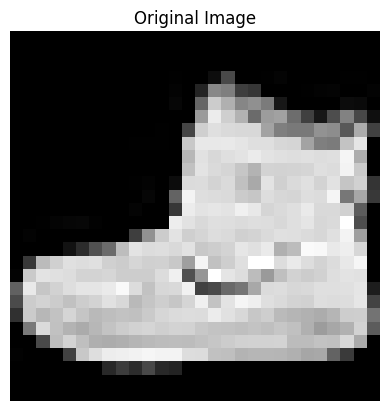

In [56]:
plt.imshow(X_train[0], cmap='gray')
plt.title("Original Image")
plt.axis('off')
plt.show()

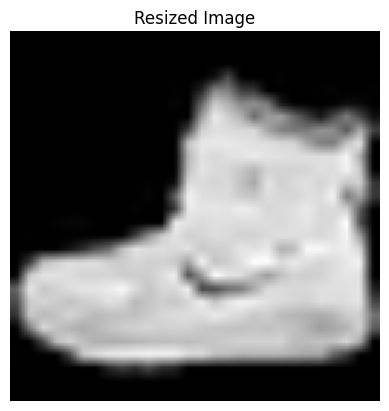

In [57]:
img = X_train[0]

resized = cv2.resize(img, (128, 128))

plt.imshow(resized, cmap='gray')
plt.title("Resized Image")
plt.axis('off')
plt.show()

In [58]:
img_norm = X_train / 255.0

print(img_norm.min())
print(img_norm.max())

0.0
1.0


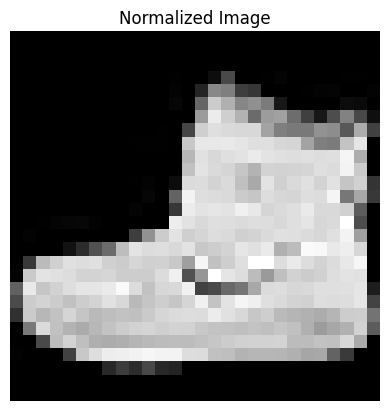

In [59]:
plt.imshow(img_norm[0], cmap='gray')
plt.title("Normalized Image")
plt.axis('off')
plt.show()

In [60]:
mean = np.mean(X_train)
std = np.std(X_train)

img_std = (X_train - mean) / std

print(np.mean(img_std))
print(np.std(img_std))

-1.74808013869143e-17
1.0


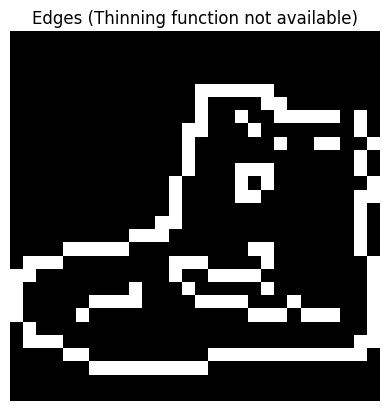

In [61]:
img = X_train[0]

edges = cv2.Canny(img, 100, 200)

# thin_edges = cv2.ximgproc.thinning(edges) # This function is not available in the current OpenCV installation.

plt.imshow(edges, cmap='gray') # Displaying edges instead, as thinning is not available.
plt.title("Edges (Thinning function not available)")
plt.axis('off')
plt.show()

In [ ]:
import os

# Dataset from Kaggle (2.7GB)
!kaggle datasets download -d vipoooool/new-plant-diseases-dataset --unzip

base_path = "New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)"
train_path = os.path.join(base_path, "train")

if os.path.exists(train_path):
    classes = sorted([c for c in os.listdir(train_path) if os.path.isdir(os.path.join(train_path, c))])
    print(f"Tổng số lớp bệnh: {len(classes)}")
    print(f"5 lớp đầu tiên: {classes[:5]}")
else:
    print("Đường dẫn không tồn tại. Kiểm tra lại cấu trúc thư mục sau khi unzip!")

Dataset URL: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset
License(s): copyright-authors
100% 2.70G/2.70G [01:57<00:00, 24.8MB/s]

Tổng số lớp bệnh: 38
5 lớp đầu tiên: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


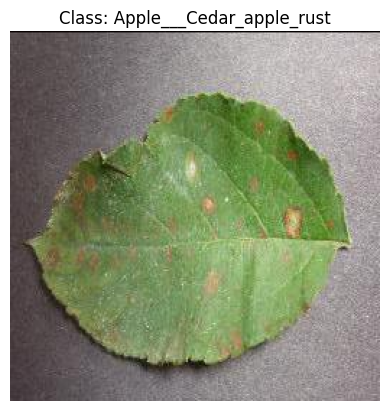

In [63]:
# a) LOADING ONE IMAGE
dataset_path = "New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train"

classes = sorted([c for c in os.listdir(dataset_path)
                  if os.path.isdir(os.path.join(dataset_path, c))])

class_name = classes[2]

class_path = os.path.join(dataset_path, class_name)
images = [img for img in os.listdir(class_path)
          if img.lower().endswith(('.png', '.jpg', '.jpeg'))]

image_path = os.path.join(class_path, images[0])
image = cv2.imread(image_path)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.title(f"Class: {class_name}")
plt.axis("off")
plt.show()

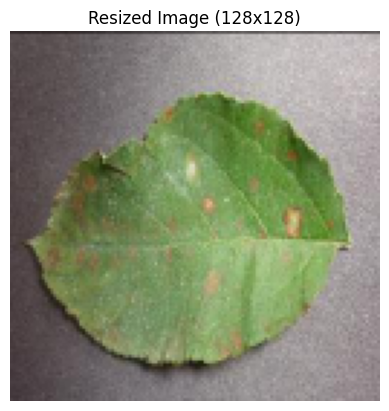

Resized Shape: (128, 128, 3)


In [64]:
# a) IMAGE RESIZING
resize_image = cv2.resize(image_rgb, (128, 128))
plt.imshow(resize_image)
plt.title("Resized Image (128x128)")
plt.axis("off")
plt.show()

print("Resized Shape:", resize_image.shape)

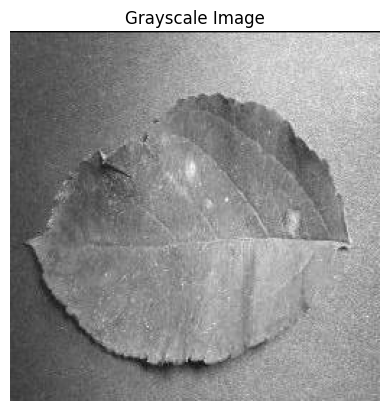

Grayscale Shape: (256, 256)


In [65]:
# b) GRAYSCALE CONVERSION
# =========================================================
gray_image = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

plt.imshow(gray_image, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

print("Grayscale Shape:", gray_image.shape)

Min Value: 0.01568627450980392
Max Value: 0.8980392156862745
Mean Value: 0.4875952627144607
Std Value: 0.1597230737672002


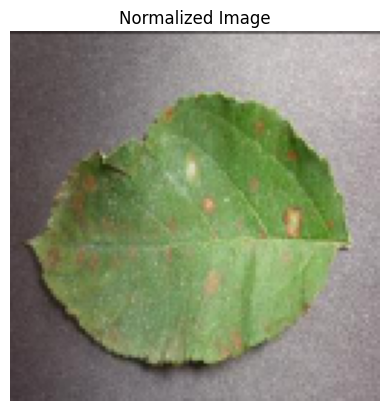

In [66]:
# b) NORMALIZATION
normalized_image = resize_image / 255.0

print("Min Value:", normalized_image.min())
print("Max Value:", normalized_image.max())
print("Mean Value:", normalized_image.mean())
print("Std Value:", normalized_image.std())

plt.imshow(normalized_image)
plt.title("Normalized Image")
plt.axis("off")
plt.show()

In [67]:
# c) STANDARDIZATION

mean = np.mean(normalized_image)
std = np.std(normalized_image)

standardized_image = (normalized_image - mean) / std

print("Mean:", standardized_image.mean())
print("Std:", standardized_image.std())

Mean: 6.268134159862863e-16
Std: 1.0


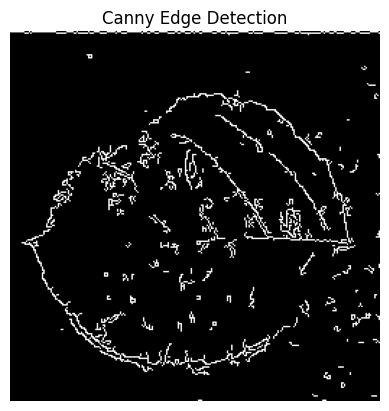

In [68]:
# d) EDGE DETECTION - CANNY
edges = cv2.Canny(gray_image, 100, 200)

plt.imshow(edges, cmap='gray')
plt.title("Canny Edge Detection")
plt.axis("off")
plt.show()